# AI651 – PA3 (Questions 1–7)
**Data for Q3–Q7:** download `ca_his_raw_2020.h5`, `ca_his_raw_2021.h5`, `ca_meta.csv`, `ca_rn_adj.npy` from Kaggle (liuxu77/largest) into a `data/` folder.

## Setup

In [1]:
# Cell 1 – Imports
import os, time, json, platform, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import torch
import torch.nn as nn

In [2]:
# Cell 2 – Helper functions
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

def get_device():
    if torch.backends.mps.is_available():
        return torch.device("mps")      # Apple M1/M2 GPU
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

In [3]:
# Cell 3 – Settings
GITHUB_URL = "https://github.com/<your-username>/<your-repo>"   # <-- put your public repo link here
STUDENT_ID = "25280065"

DATA_DIR, OUT_DIR = "data", "outputs"
FIG_DIR, MODEL_DIR = os.path.join(OUT_DIR, "figures"), os.path.join(OUT_DIR, "models")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

RAW_FILES = {2020: os.path.join(DATA_DIR, "ca_his_raw_2020.h5"),
             2021: os.path.join(DATA_DIR, "ca_his_raw_2021.h5")}
META_FILE = os.path.join(DATA_DIR, "ca_meta.csv")
ADJ_FILE  = os.path.join(DATA_DIR, "ca_rn_adj.npy")

SD_DISTRICT, EXPECTED_NODES = 11, 716       # District 11 = San Diego (as in the LargeST repo)
SPLITS = {"train": ("2020-01-01 00:00", "2020-12-31 23:45"),
          "val":   ("2021-01-01 00:00", "2021-03-31 23:45"),
          "test":  ("2021-04-01 00:00", "2021-12-31 23:45")}
T_IN, T_OUT = 8, 4

SEED = 42
set_seed(SEED)
DEVICE = get_device()

In [4]:
# Cell 4 – Show results
print("Device:", DEVICE)
for f in list(RAW_FILES.values()) + [META_FILE, ADJ_FILE]:
    print(f"{'OK     ' if os.path.exists(f) else 'MISSING'}  {f}")

Device: mps
OK       data/ca_his_raw_2020.h5
OK       data/ca_his_raw_2021.h5
OK       data/ca_meta.csv
OK       data/ca_rn_adj.npy


## Q1 – What does a sum remember?
(a) affine message loses information · (b) place-value message keeps all counts · (c) Sum vs Mean vs Max.

In [5]:
# Cell 1 – Imports
import numpy as np

In [6]:
# Cell 2 – Helper functions
def all_groups(K):
    # every (slowing, steady, speeding) count with 1..K neighbours
    return [(a, b, c) for a in range(K + 1) for b in range(K + 1) for c in range(K + 1) if 1 <= a + b + c <= K]

def combine(a, b, c, method):
    n = a + b + c
    if method == "Sum":  return (a, b, c)
    if method == "Mean": return (round(a / n, 4), round(b / n, 4), round(c / n, 4))
    if method == "Max":  return (int(a > 0), int(b > 0), int(c > 0))

def possible(task, method, K):
    # possible = the same combined vector never needs two different answers
    seen = {}
    for a, b, c in all_groups(K):
        key, ans = combine(a, b, c, method), task(a, b, c)
        if key in seen and seen[key] != ans:
            return "No"
        seen[key] = ans
    return "Yes"

In [7]:
# Cell 3 – Calling the functions
K = 8

# (a) same n_v and S_v, different number of steady neighbours
w, c0 = 2, 5
group_A, group_B = [0, 0], [-1, 1]
total_A = sum(w * x + c0 for x in group_A)
total_B = sum(w * x + c0 for x in group_B)

# (b) base B = K+1 -> phi(-1)=1, phi(0)=9, phi(+1)=81
BASE = K + 1
phi = np.array([1, BASE, BASE ** 2])
groups = np.array(all_groups(K))                 # (164, 3)
totals = groups @ phi                            # NumPy: sum of messages
decoded = np.stack([totals % BASE, (totals // BASE) % BASE, totals // BASE ** 2], axis=1)
all_unique = len(np.unique(totals)) == len(totals)
decode_ok = bool((decoded == groups).all())
nonsteady_ok = bool((groups @ np.array([1, 0, 1]) == groups[:, 0] + groups[:, 2]).all())   # phi(x)=x^2

# (c)
tasks = {"Count steady neighbours": lambda a, b, c: b,
         "More than half slowing":  lambda a, b, c: a > (a + b + c) / 2,
         "Any neighbour slowing":   lambda a, b, c: a > 0}
q1_table = {(t, m): possible(f, m, K) for t, f in tasks.items() for m in ["Sum", "Mean", "Max"]}

In [8]:
# Cell 4 – Show results
print("(a) total A =", total_A, "| total B =", total_B, "| identical:", total_A == total_B)
print("(b) phi =", phi.tolist(), "| groups checked:", len(groups), "| all sums unique:", all_unique,
      "| decode OK:", decode_ok, "| non-steady phi=x^2 OK:", nonsteady_ok)
print("    example (3,2,1) -> sum", int(np.array([3, 2, 1]) @ phi))
print("(c)")
for (t, m), ans in q1_table.items():
    print(f"    {t:25s} {m:5s} {ans}")

(a) total A = 10 | total B = 10 | identical: True
(b) phi = [1, 9, 81] | groups checked: 164 | all sums unique: True | decode OK: True | non-steady phi=x^2 OK: True
    example (3,2,1) -> sum 102
(c)
    Count steady neighbours   Sum   Yes
    Count steady neighbours   Mean  No
    Count steady neighbours   Max   No
    More than half slowing    Sum   Yes
    More than half slowing    Mean  Yes
    More than half slowing    Max   No
    Any neighbour slowing     Sum   Yes
    Any neighbour slowing     Mean  Yes
    Any neighbour slowing     Max   Yes


## Q2 – Which way is the slowdown moving?
40-sensor ring; the jam moves one sensor backwards per step: x_i(t+1) = x_{i+1}(t).

In [9]:
# Cell 1 – Imports
import numpy as np
import matplotlib.pyplot as plt

In [10]:
# Cell 2 – Helper functions
N_RING = 40
def left(x):  return np.roll(x, 1)     # x[i-1]
def right(x): return np.roll(x, -1)    # x[i+1]
def true_step(x): return right(x)

def layer_a(x, a, b):        return a * x + b * (left(x) + right(x))
def layer_b(x, a, wm, wp):   return a * x + wm * left(x) + wp * right(x)
def layer_c(x, xp, a, b, c): return a * x + b * (left(x) + right(x)) + c * xp

def fit_ab(x, target):
    X = np.column_stack([x, left(x) + right(x)])
    (a, b), *_ = np.linalg.lstsq(X, target, rcond=None)
    return a, b

def run(x0, step, steps=20):
    xs = [x0]
    for _ in range(steps):
        xs.append(step(xs[-1]))
    return np.array(xs)

In [11]:
# Cell 3 – Calling the functions
# (a)i single jam at sensor 20
x_spike = np.zeros(N_RING); x_spike[20] = 1
target = true_step(x_spike)
a_fit, b_fit = fit_ab(x_spike, target)
pred_spike = layer_a(x_spike, a_fit, b_fit)
sse_a = float(np.sum((pred_spike - target) ** 2))

# (a)ii smooth bump, 20 steps
bump = np.exp(-(np.arange(N_RING) - 20) ** 2 / 8)
model_run = run(bump, lambda x: layer_a(x, a_fit, b_fit))
true_run = run(bump, true_step)

# (b) direction-aware weights: a=0, w-=0, w+=1  -> kernel [0,0,1], circular padding
x_rand = np.random.rand(N_RING)
q2b_ok = np.allclose(layer_b(x_rand, 0, 0, 1), true_step(x_rand))

# (c) history: a=0, b=1, c=-1
x_prev = np.random.rand(N_RING)
x_now = np.roll(x_prev, -1)
q2c_back_ok = np.allclose(layer_c(x_now, x_prev, 0, 1, -1), np.roll(x_now, -1))   # backward motion
x_now = np.roll(x_prev, 1)
q2c_fwd_ok = np.allclose(layer_c(x_now, x_prev, 0, 1, -1), np.roll(x_now, 1))     # forward motion

(a)i  a = 0.000, b = 0.500, squared error = 0.500
      sensors 19/20/21 predicted: [0.5 0.  0.5] correct: [1. 0. 0.]
(b)   exact: True | kernel [x_i-1, x_i, x_i+1] = [0, 0, 1], circular padding
(c)i  backward exact: True | (c)ii forward exact: True


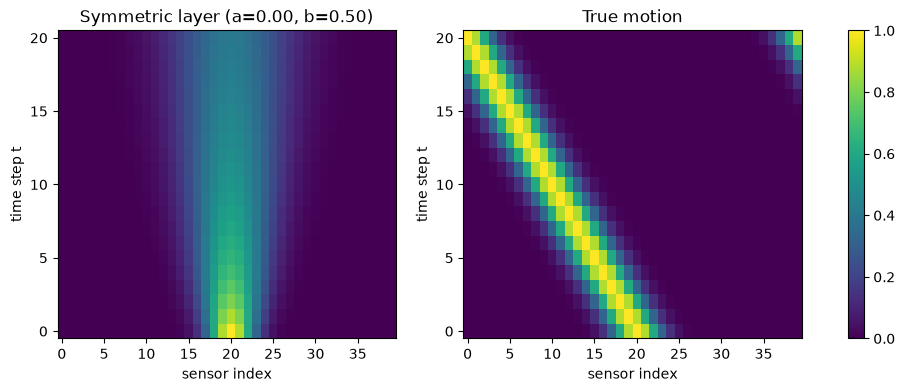

In [12]:
# Cell 4 – Show results
print(f"(a)i  a = {a_fit:.3f}, b = {b_fit:.3f}, squared error = {sse_a:.3f}")
print("      sensors 19/20/21 predicted:", pred_spike[19:22].round(3), "correct:", target[19:22])
print("(b)   exact:", q2b_ok, "| kernel [x_i-1, x_i, x_i+1] = [0, 0, 1], circular padding")
print("(c)i  backward exact:", q2c_back_ok, "| (c)ii forward exact:", q2c_fwd_ok)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for axis, data_, title in [(ax[0], model_run, f"Symmetric layer (a={a_fit:.2f}, b={b_fit:.2f})"),
                           (ax[1], true_run, "True motion")]:
    im = axis.imshow(data_, aspect="auto", origin="lower", vmin=0, vmax=1, cmap="viridis")
    axis.set_title(title); axis.set_xlabel("sensor index"); axis.set_ylabel("time step t")
    axis.set_yticks(range(0, 21, 5))
fig.colorbar(im, ax=ax)
savefig("q2a_heatmaps.png"); plt.show()

## Q3(a) – Data extraction and resampling
Flow is a vehicle **count** per 5 min, so the 15-min value = sum of 3 readings (computed as mean × 3 so 1–2 missing readings don't undercount). Missing targets are masked; inputs are forward-filled inside each split (Q4a).

In [13]:
# Cell 1 – Imports
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

In [14]:
# Cell 2 – Helper functions
def load_sd_meta(meta_file, district):
    meta = pd.read_csv(meta_file)
    sd = meta[meta["District"] == district].reset_index(drop=True)
    sd["ID"] = sd["ID"].astype(str)
    return sd

def _to_str(arr):
    return [a.decode() if isinstance(a, bytes) else str(a) for a in arr]

def read_columns_h5(path, columns, chunk_rows=2000):
    # read only the San Diego columns from the big California file (saves RAM)
    try:
        with h5py.File(path, "r") as f:
            g = f[list(f.keys())[0]]
            kind = g["axis1"].attrs.get("kind", b"datetime64")
            kind = kind.decode() if isinstance(kind, bytes) else str(kind)
            unit = kind.split("[")[1].rstrip("]") if "[" in kind else "ns"
            index = pd.to_datetime(g["axis1"][:], unit=unit)
            pos = {c: k for k, c in enumerate(_to_str(g["block0_items"][:]))}
            want = np.array([pos[c] for c in columns])
            order = np.argsort(want)
            values = g["block0_values"]
            if values.shape[0] == len(index):        # (time, sensors)
                data = np.concatenate([values[s:s + chunk_rows][:, want[order]]
                                       for s in range(0, len(index), chunk_rows)])
            else:                                    # (sensors, time)
                data = values[want[order], :].T
            data = data[:, np.argsort(order)]
        df = pd.DataFrame(data.astype(np.float32), index=index, columns=columns)
    except Exception as e:
        print("fast reader failed (", e, ") -> using pd.read_hdf")
        df = pd.read_hdf(path)
        df.columns = df.columns.astype(str)
        df = df[columns].astype(np.float32)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    return df

def build_sd_flow(raw_files, sensor_ids):
    parts, n_nan, n_all = [], 0, 0
    for year, path in raw_files.items():
        print("Reading", path, "...")
        df5 = read_columns_h5(path, sensor_ids)
        df5 = df5[df5.index.year == year]
        n_nan += int(df5.isna().values.sum()); n_all += df5.size
        parts.append(df5.resample("15min").mean() * 3)     # 15-min vehicle count
        del df5
    full_index = pd.date_range(SPLITS["train"][0], SPLITS["test"][1], freq="15min")
    return pd.concat(parts).reindex(full_index), 100 * n_nan / n_all

In [15]:
# Cell 3 – Calling the functions
sd_meta = load_sd_meta(META_FILE, SD_DISTRICT)
sensor_ids = sd_meta["ID"].tolist()
assert len(sensor_ids) == EXPECTED_NODES, f"Expected {EXPECTED_NODES} sensors, got {len(sensor_ids)}"

CACHE_FLOW = os.path.join(DATA_DIR, "sd_flow_15min.pkl")
CACHE_INFO = os.path.join(DATA_DIR, "sd_flow_info.json")
if os.path.exists(CACHE_FLOW):
    flow15 = pd.read_pickle(CACHE_FLOW)
    missing_5min_pct = json.load(open(CACHE_INFO))["missing_5min_pct"]
else:
    flow15, missing_5min_pct = build_sd_flow(RAW_FILES, sensor_ids)
    flow15.to_pickle(CACHE_FLOW)
    json.dump({"missing_5min_pct": missing_5min_pct}, open(CACHE_INFO, "w"))
assert list(flow15.columns) == sensor_ids

missing_15min_pct = 100 * flow15.isna().values.mean()
missing_per_sensor = 100 * flow15.isna().mean()
plot_sensors = missing_per_sensor.nsmallest(3).index.tolist()
week = flow15.loc["2020-02-03":"2020-02-09 23:45", plot_sensors]

Shape (time steps, sensors): (70176, 716) | 2020-01-01 00:00:00 -> 2021-12-31 23:45:00
Missing: 5-min 5.07% | 15-min 5.06% | sensors >50% missing: 43 | fully missing: 19


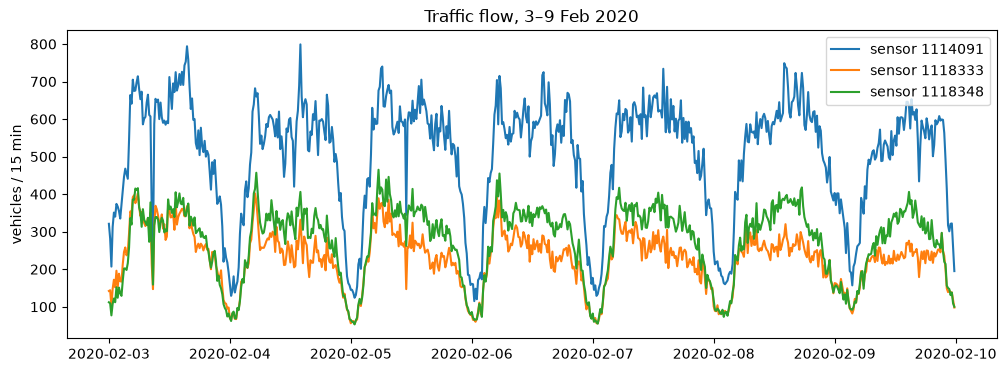

In [16]:
# Cell 4 – Show results
print("Shape (time steps, sensors):", flow15.shape, "|", flow15.index[0], "->", flow15.index[-1])
print(f"Missing: 5-min {missing_5min_pct:.2f}% | 15-min {missing_15min_pct:.2f}% | "
      f"sensors >50% missing: {int((missing_per_sensor > 50).sum())} | fully missing: {int((missing_per_sensor == 100).sum())}")

plt.figure(figsize=(12, 4))
for s in plot_sensors:
    plt.plot(week.index, week[s], label=f"sensor {s}")
plt.ylabel("vehicles / 15 min"); plt.title("Traffic flow, 3–9 Feb 2020"); plt.legend()
savefig("q3a_one_week.png"); plt.show()

## Q3(b) – Constructing the traffic graph
Rows/columns taken with `ID2` from the same `sd_meta` rows as the data columns, so the order matches.

In [17]:
# Cell 1 – Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [18]:
# Cell 2 – Helper functions
def load_sd_adj(adj_file, sd_meta):
    ca_adj = np.load(adj_file, mmap_mode="r")
    idx = sd_meta["ID2"].values
    return np.array(ca_adj[idx][:, idx], dtype=np.float32)

def remove_self_loops(A):
    A = A.copy(); np.fill_diagonal(A, 0)
    return A

def graph_stats(A, A_nd):
    N = A.shape[0]
    return pd.Series({
        "nodes": N,
        "nonzero edges (no self-loops)": int(np.count_nonzero(A_nd)),
        "self-loops on diagonal": int(np.count_nonzero(np.diag(A))),
        "symmetric": bool(np.allclose(A, A.T)),
        "density (%)": round(100 * np.count_nonzero(A_nd) / (N * (N - 1)), 3),
        "weight range": f"{A_nd[A_nd > 0].min():.3f} – {A_nd[A_nd > 0].max():.3f}"})

In [19]:
# Cell 3 – Calling the functions
A_sd = load_sd_adj(ADJ_FILE, sd_meta)
A_nd = remove_self_loops(A_sd)
IS_SYMMETRIC = bool(np.allclose(A_sd, A_sd.T))
out_degree = np.count_nonzero(A_nd, axis=1)          # N(i) = {j : A_ij != 0}
stats_graph = graph_stats(A_sd, A_nd)

nodes                                      716
nonzero edges (no self-loops)            17319
self-loops on diagonal                     716
symmetric                                False
density (%)                              3.383
weight range                     0.010 – 1.000
Neighbours per sensor: mean 24.19, median 20, max 70, isolated 8


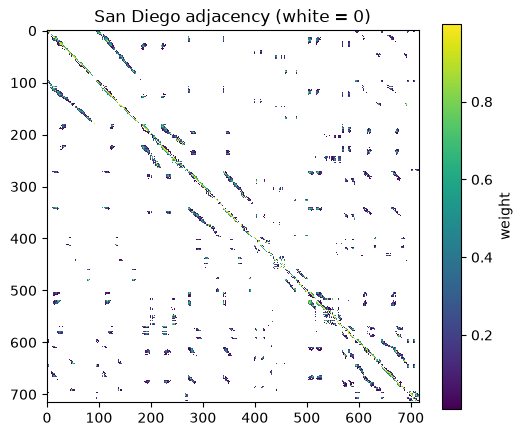

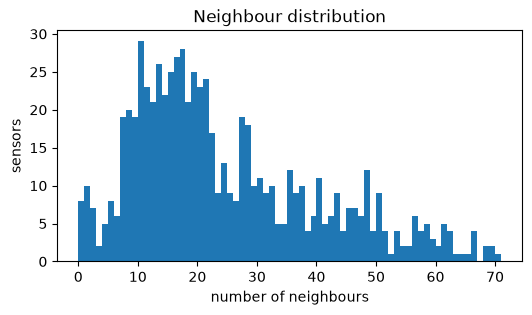

In [20]:
# Cell 4 – Show results
print(stats_graph.to_string())
print(f"Neighbours per sensor: mean {out_degree.mean():.2f}, median {np.median(out_degree):.0f}, "
      f"max {out_degree.max()}, isolated {int((out_degree == 0).sum())}")

plt.figure(figsize=(6, 5))
plt.imshow(np.where(A_nd > 0, A_nd, np.nan), cmap="viridis", interpolation="nearest")
plt.colorbar(label="weight"); plt.title("San Diego adjacency (white = 0)")
savefig("q3b_adjacency_heatmap.png"); plt.show()

plt.figure(figsize=(6, 3))
plt.hist(out_degree, bins=range(0, out_degree.max() + 2))
plt.xlabel("number of neighbours"); plt.ylabel("sensors"); plt.title("Neighbour distribution")
savefig("q3b_degree_hist.png"); plt.show()

## Q3(c) – Graph neighbourhoods

In [21]:
# Cell 1 – Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [22]:
# Cell 2 – Helper functions
def neighbourhoods(A_nd, i):
    B = (A_nd > 0).astype(np.float32)
    one_hop = np.nonzero(B[i])[0]
    reach = (B[i] + B[i] @ B) > 0           # paths of at most 2 edges
    reach[i] = False
    return one_hop, np.setdiff1d(np.nonzero(reach)[0], one_hop)

def neighbour_correlation(flow_train, i, one_hop, two_hop):
    corr = flow_train.corrwith(flow_train.iloc[:, i])
    others = np.setdiff1d(np.arange(flow_train.shape[1]), np.concatenate([[i], one_hop, two_hop]))
    return pd.Series({"1-hop": corr.iloc[one_hop].mean(), "2-hop": corr.iloc[two_hop].mean(),
                      "others": corr.iloc[others].mean()})

In [23]:
# Cell 3 – Calling the functions
candidates = np.argsort(np.abs(out_degree - np.median(out_degree)))[:20]
sel = int(candidates[np.argmin(missing_per_sensor.values[candidates])])
one_hop, two_hop = neighbourhoods(A_nd, sel)
flow_train = flow15.loc[SPLITS["train"][0]:SPLITS["train"][1]]
corr_table = neighbour_correlation(flow_train, sel, one_hop, two_hop)

Sensor 1126411 | 1-hop (20): ['1114805', '1114035', '1108547', '1118707', '1117871', '1108615', '1117818', '1126426', '1114806', '1108711', '1108693', '1111514', '1113486', '1115356', '1115413', '1115432', '1115438', '1116574', '1115528', '1115517']
2-hop only (53): ['1117748', '1113976', '1117741', '1108603', '1117835', '1117717', '1118078', '1108611', '1108613', '1114050', '1108617', '1118496', '1118521', '1108665', '1117683', '1108417', '1117734', '1108605', '1118702', '1108609', '1108728', '1114540', '1111551', '1115420', '1115426', '1111566', '1115444', '1116783', '1114546', '1115555', '1115565', '1111552', '1116165', '1115548', '1111540', '1115572', '1121818', '1114450', '1114457', '1113279', '1111539', '1108331', '1111520', '1121821', '1114463', '1111509', '1121288', '1116112', '1113460', '1108572', '1115921', '1108391', '1115929']
Mean flow correlation (2020): {'1-hop': 0.918, '2-hop': 0.919, 'others': 0.885}


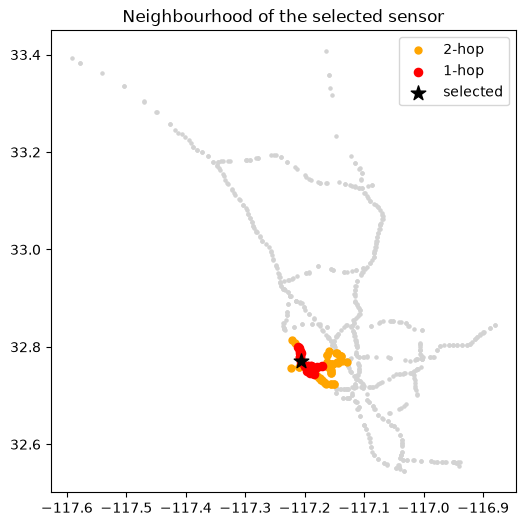

In [24]:
# Cell 4 – Show results
ids = np.array(sensor_ids)
print(f"Sensor {ids[sel]} | 1-hop ({len(one_hop)}): {ids[one_hop].tolist()}")
print(f"2-hop only ({len(two_hop)}): {ids[two_hop].tolist()}")
print("Mean flow correlation (2020):", corr_table.round(3).to_dict())

plt.figure(figsize=(6, 6))
plt.scatter(sd_meta.Lng, sd_meta.Lat, s=5, c="lightgrey")
plt.scatter(sd_meta.Lng[two_hop], sd_meta.Lat[two_hop], s=25, c="orange", label="2-hop")
plt.scatter(sd_meta.Lng[one_hop], sd_meta.Lat[one_hop], s=35, c="red", label="1-hop")
plt.scatter(sd_meta.Lng[sel], sd_meta.Lat[sel], s=120, c="black", marker="*", label="selected")
plt.legend(); plt.title("Neighbourhood of the selected sensor")
savefig("q3c_neighbourhood_map.png"); plt.show()

## Q4(a) – Forecasting windows
Per-sensor z-score from **training data only**; each split processed separately so no window crosses a boundary.

In [25]:
# Cell 1 – Imports
import numpy as np
import pandas as pd
import torch

In [26]:
# Cell 2 – Helper functions
def training_stats(train_df):
    return train_df.mean().fillna(0.0), train_df.std().replace(0, np.nan).fillna(1.0)

def prepare_split(df, mean, std, device):
    mask = df.notna().values                               # True = real reading
    x = ((df.ffill().fillna(mean) - mean) / std).values    # past-only fill inside this split
    y = df.fillna(0.0).values                              # missing targets are masked
    return {"x": torch.tensor(x, dtype=torch.float32, device=device),
            "y": torch.tensor(y, dtype=torch.float32, device=device),
            "mask": torch.tensor(mask, device=device),
            "starts": np.arange(T_IN - 1, len(df) - T_OUT),   # t = last input step
            "index": df.index}

IN_OFFSETS, OUT_OFFSETS = torch.arange(-(T_IN - 1), 1), torch.arange(1, T_OUT + 1)

def get_batch(split, t):
    t = torch.as_tensor(t).view(-1, 1)
    i_in, i_out = (t + IN_OFFSETS).to(split["x"].device), (t + OUT_OFFSETS).to(split["x"].device)
    return split["x"][i_in], split["y"][i_out], split["mask"][i_out]    # (B,8,N) (B,4,N) (B,4,N)

In [27]:
# Cell 3 – Calling the functions
split_frames = {n: flow15.loc[s:e] for n, (s, e) in SPLITS.items()}
train_mean, train_std = training_stats(split_frames["train"])
data = {n: prepare_split(df, train_mean, train_std, DEVICE) for n, df in split_frames.items()}
MEAN_T = torch.tensor(train_mean.values, dtype=torch.float32, device=DEVICE)
STD_T  = torch.tensor(train_std.values,  dtype=torch.float32, device=DEVICE)
xb, yb, _ = get_batch(data["train"], data["train"]["starts"][:1])

In [28]:
# Cell 4 – Show results
for n, d in data.items():
    print(f"{n:5s}: {d['index'][0]} -> {d['index'][-1]} | windows = {len(d['starts'])}")
print("X_t:", tuple(xb[0].unsqueeze(-1).shape), "| Y_t:", tuple(yb[0].unsqueeze(-1).shape))

train: 2020-01-01 00:00:00 -> 2020-12-31 23:45:00 | windows = 35125
val  : 2021-01-01 00:00:00 -> 2021-03-31 23:45:00 | windows = 8629
test : 2021-04-01 00:00:00 -> 2021-12-31 23:45:00 | windows = 26389
X_t: (8, 716, 1) | Y_t: (4, 716, 1)


## Q4(b) – Spatio-temporal model
Temporal Conv1d encoder → H = ReLU(Â Z W_g) + Z (residual) → linear head (4 steps). Â = D^-1/2(A+I)D^-1/2 if A is symmetric, else D^-1(A+I). Loss: masked MAE; metrics in vehicles/15 min.

In [29]:
# Cell 1 – Imports
import os, time, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

In [30]:
# Cell 2 – Helper functions
def normalize_adj(A, symmetric):
    A = A.copy(); np.fill_diagonal(A, 0)
    A_tilde = A + np.eye(A.shape[0], dtype=np.float32)
    deg = A_tilde.sum(axis=1)
    if symmetric:
        d = deg ** -0.5
        return (d[:, None] * A_tilde * d[None, :]).astype(np.float32)
    return (A_tilde / deg[:, None]).astype(np.float32)

class TemporalEncoder(nn.Module):              # (B, 8, N) -> (B, N, d)
    def __init__(self, d, t_in=T_IN):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(1, d, 3), nn.ReLU(), nn.Conv1d(d, d, 3), nn.ReLU())
        self.proj = nn.Linear(d * (t_in - 4), d)
    def forward(self, x):
        B, T, N = x.shape
        z = self.conv(x.permute(0, 2, 1).reshape(B * N, 1, T)).reshape(B * N, -1)
        return self.proj(z).reshape(B, N, -1)

class GraphConv(nn.Module):                    # H = ReLU(A Z W) + Z; A=None -> no neighbour mixing
    def __init__(self, d):
        super().__init__()
        self.W = nn.Linear(d, d)
    def forward(self, Z, A=None):
        AZ = Z if A is None else torch.einsum("nm,bmd->bnd", A, Z)
        return torch.relu(self.W(AZ)) + Z      # residual: each sensor keeps its own temporal features

class STGNN(nn.Module):                        # mode: none / fixed / adaptive / hybrid
    def __init__(self, n_nodes, d=32, mode="fixed", A_fixed=None, emb_dim=10):
        super().__init__()
        self.mode = mode
        self.encoder, self.gconv, self.head = TemporalEncoder(d), GraphConv(d), nn.Linear(d, T_OUT)
        if mode in ("fixed", "hybrid"):
            self.register_buffer("A_fixed", torch.tensor(A_fixed))
        if mode in ("adaptive", "hybrid"):
            self.E1 = nn.Parameter(torch.randn(n_nodes, emb_dim))
            self.E2 = nn.Parameter(torch.randn(n_nodes, emb_dim))
        if mode == "hybrid":
            self.alpha_logit = nn.Parameter(torch.zeros(()))      # alpha starts at 0.5

    def adaptive_adj(self):
        return torch.softmax(torch.relu(self.E1 @ self.E2.T), dim=1)
    def alpha(self):
        return torch.sigmoid(self.alpha_logit)
    def adjacency(self):
        if self.mode == "none":     return None
        if self.mode == "fixed":    return self.A_fixed
        if self.mode == "adaptive": return self.adaptive_adj()
        return self.alpha() * self.A_fixed + (1 - self.alpha()) * self.adaptive_adj()

    def forward(self, x):
        return self.head(self.gconv(self.encoder(x), self.adjacency())).permute(0, 2, 1)   # (B, 4, N)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, split, batch_size=256):
    model.eval()
    abs_sum, sq_sum, count = 0.0, 0.0, 0
    for s in range(0, len(split["starts"]), batch_size):
        x, y, m = get_batch(split, split["starts"][s:s + batch_size])
        err = ((model(x) * STD_T + MEAN_T).clamp(min=0) - y)[m]
        abs_sum += err.abs().sum().item(); sq_sum += (err ** 2).sum().item(); count += int(m.sum().item())
    return abs_sum / count, (sq_sum / count) ** 0.5

def train_model(model, hp):
    opt = torch.optim.Adam(model.parameters(), lr=hp["lr"])
    rng = np.random.default_rng(hp["seed"])
    best_val, best_state, wait, history = np.inf, None, 0, []
    start = time.time()
    for epoch in range(1, hp["epochs"] + 1):
        model.train()
        starts, losses = rng.permutation(data["train"]["starts"]), []
        for s in range(0, len(starts), hp["batch_size"]):
            x, y, m = get_batch(data["train"], starts[s:s + hp["batch_size"]])
            loss = (model(x) - (y - MEAN_T) / STD_T).abs()[m].mean()     # masked MAE
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), hp["grad_clip"])
            opt.step(); losses.append(loss.item())
        val_mae, val_rmse = evaluate(model, data["val"])
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "val_mae": val_mae})
        print(f"  epoch {epoch:2d} | loss {np.mean(losses):.4f} | val MAE {val_mae:.2f} | {time.time() - start:.0f}s")
        if val_mae < best_val:
            best_val, wait = val_mae, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= hp["patience"]:
                print("  early stopping"); break
    model.load_state_dict(best_state)
    return time.time() - start, history

RUN_TAG = "residual"                           # new tag -> old (non-residual) runs are not reused
RESULTS_FILE = os.path.join(OUT_DIR, f"results_{RUN_TAG}.json")
RESULTS = json.load(open(RESULTS_FILE)) if os.path.exists(RESULTS_FILE) else {}

def run_experiment(name, label, adj_name, mode, A_fixed, hp, retrain=False):
    set_seed(hp["seed"])
    model = STGNN(EXPECTED_NODES, hp["d_hidden"], mode, A_fixed, hp["emb_dim"]).to(DEVICE)
    path = os.path.join(MODEL_DIR, f"{name}_{RUN_TAG}.pt")
    if os.path.exists(path) and name in RESULTS and not retrain:
        model.load_state_dict(torch.load(path, map_location=DEVICE))
        print(f"{name}: loaded saved model")
        return model
    print(f"Training {name} ({count_params(model)} params) on {DEVICE}")
    train_time, history = train_model(model, hp)
    (val_mae, val_rmse), (test_mae, test_rmse) = evaluate(model, data["val"]), evaluate(model, data["test"])
    torch.save(model.state_dict(), path)
    RESULTS[name] = {"Model": label, "Adjacency": adj_name, "Val MAE": val_mae, "Val RMSE": val_rmse,
                     "Test MAE": test_mae, "Test RMSE": test_rmse, "Training time (s)": train_time,
                     "Epochs": len(history), "Params": count_params(model), "history": history}
    json.dump(RESULTS, open(RESULTS_FILE, "w"), indent=2)
    return model

def results_table(names):
    cols = ["Model", "Adjacency", "Val MAE", "Val RMSE", "Test MAE", "Test RMSE", "Training time (s)", "Epochs", "Params"]
    return pd.DataFrame([RESULTS[n] for n in names])[cols].round(2)

In [31]:
# Cell 3 – Calling the functions
HP = {"d_hidden": 32, "emb_dim": 10, "lr": 1e-3, "batch_size": 64, "epochs": 30,
      "patience": 5, "grad_clip": 5.0, "seed": SEED}

A_hat_fixed = normalize_adj(A_sd, IS_SYMMETRIC)        # fixed model (Q4b / Q5a)
A_row_fixed = normalize_adj(A_sd, False)               # row-normalised, for the hybrid (Q5c)
FIXED_NORM = "D^-1/2 (A+I) D^-1/2" if IS_SYMMETRIC else "D^-1 (A+I) (row-normalised, directed graph)"
model_fixed = run_experiment("stgnn_fixed", "STGNN", "Fixed", "fixed", A_hat_fixed, HP)

Training stgnn_fixed (8548 params) on mps
  epoch  1 | loss 0.1875 | val MAE 56.13 | 30s
  epoch  2 | loss 0.1439 | val MAE 54.50 | 56s
  epoch  3 | loss 0.1411 | val MAE 54.58 | 82s
  epoch  4 | loss 0.1399 | val MAE 53.95 | 109s
  epoch  5 | loss 0.1387 | val MAE 53.04 | 135s
  epoch  6 | loss 0.1376 | val MAE 53.68 | 161s
  epoch  7 | loss 0.1367 | val MAE 52.91 | 187s
  epoch  8 | loss 0.1361 | val MAE 53.09 | 213s
  epoch  9 | loss 0.1359 | val MAE 51.73 | 240s
  epoch 10 | loss 0.1352 | val MAE 51.85 | 266s
  epoch 11 | loss 0.1346 | val MAE 52.21 | 293s
  epoch 12 | loss 0.1344 | val MAE 51.49 | 319s
  epoch 13 | loss 0.1340 | val MAE 52.62 | 344s
  epoch 14 | loss 0.1335 | val MAE 50.52 | 369s
  epoch 15 | loss 0.1332 | val MAE 50.57 | 395s
  epoch 16 | loss 0.1331 | val MAE 50.53 | 420s
  epoch 17 | loss 0.1327 | val MAE 50.55 | 444s
  epoch 18 | loss 0.1326 | val MAE 50.38 | 469s
  epoch 19 | loss 0.1324 | val MAE 50.49 | 494s
  epoch 20 | loss 0.1317 | val MAE 50.20 | 520s
 

Normalisation: D^-1 (A+I) (row-normalised, directed graph)


,Model,Adjacency,Val MAE,Val RMSE,Test MAE,Test RMSE,Training time (s),Epochs,Params
0,STGNN,Fixed,49.38,79.77,58.42,92.09,743.21,29,8548


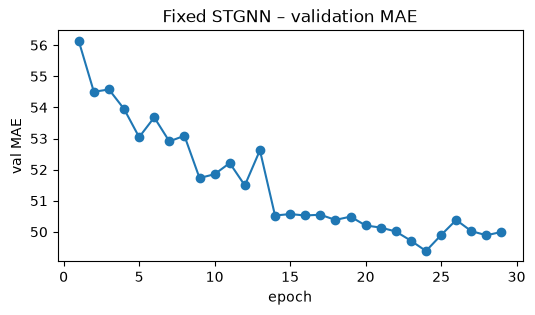

In [32]:
# Cell 4 – Show results
print("Normalisation:", FIXED_NORM)
display(results_table(["stgnn_fixed"]))
h = pd.DataFrame(RESULTS["stgnn_fixed"]["history"])
plt.figure(figsize=(6, 3)); plt.plot(h.epoch, h.val_mae, marker="o")
plt.xlabel("epoch"); plt.ylabel("val MAE"); plt.title("Fixed STGNN – validation MAE")
savefig("q4b_val_curve.png"); plt.show()

## Q4(c) – Temporal-only baseline (same encoder/head, no graph mixing, same #params)

In [33]:
# Cell 1 – Imports
import pandas as pd

In [34]:
# Cell 2 – Helper functions
def improvement(base, new):
    return 100 * (base - new) / base

In [35]:
# Cell 3 – Calling the functions
model_temporal = run_experiment("temporal_only", "Temporal-only", "None", "none", None, HP)
mae_gain = improvement(RESULTS["temporal_only"]["Test MAE"], RESULTS["stgnn_fixed"]["Test MAE"])
rmse_gain = improvement(RESULTS["temporal_only"]["Test RMSE"], RESULTS["stgnn_fixed"]["Test RMSE"])

Training temporal_only (8548 params) on mps
  epoch  1 | loss 0.1889 | val MAE 57.68 | 24s
  epoch  2 | loss 0.1481 | val MAE 56.35 | 48s
  epoch  3 | loss 0.1457 | val MAE 55.89 | 72s
  epoch  4 | loss 0.1448 | val MAE 55.55 | 96s
  epoch  5 | loss 0.1441 | val MAE 55.42 | 120s
  epoch  6 | loss 0.1435 | val MAE 56.54 | 144s
  epoch  7 | loss 0.1429 | val MAE 54.99 | 168s
  epoch  8 | loss 0.1427 | val MAE 55.26 | 192s
  epoch  9 | loss 0.1425 | val MAE 54.58 | 216s
  epoch 10 | loss 0.1424 | val MAE 54.49 | 239s
  epoch 11 | loss 0.1416 | val MAE 55.14 | 263s
  epoch 12 | loss 0.1417 | val MAE 54.25 | 288s
  epoch 13 | loss 0.1413 | val MAE 54.27 | 312s
  epoch 14 | loss 0.1409 | val MAE 54.69 | 335s
  epoch 15 | loss 0.1408 | val MAE 53.86 | 360s
  epoch 16 | loss 0.1407 | val MAE 53.88 | 384s
  epoch 17 | loss 0.1406 | val MAE 53.67 | 408s
  epoch 18 | loss 0.1405 | val MAE 53.58 | 432s
  epoch 19 | loss 0.1402 | val MAE 54.04 | 456s
  epoch 20 | loss 0.1399 | val MAE 54.03 | 481s


In [36]:
# Cell 4 – Show results
display(results_table(["temporal_only", "stgnn_fixed"]))
print(f"Graph vs temporal-only (test): MAE {mae_gain:+.1f}%, RMSE {rmse_gain:+.1f}% (positive = graph better)")

,Model,Adjacency,Val MAE,Val RMSE,Test MAE,Test RMSE,Training time (s),Epochs,Params
0,Temporal-only,None,52.96,85.37,61.58,96.77,723.40,30,8548
1,STGNN,Fixed,49.38,79.77,58.42,92.09,743.21,29,8548


Graph vs temporal-only (test): MAE +5.1%, RMSE +4.8% (positive = graph better)


## Q5 – Fixed vs adaptive vs hybrid adjacency
(a) fixed = Q4(b) model · (b) A = Softmax(ReLU(E1 E2ᵀ)), dense (no top-k) · (c) α·row-norm(A+I) + (1−α)·A_adaptive, α = sigmoid(θ) learned.

In [37]:
# Cell 1 – Imports
import numpy as np
import matplotlib.pyplot as plt
import torch

In [38]:
# Cell 2 – Helper functions
def learned_adjacency(model):
    with torch.no_grad():
        return model.adaptive_adj().cpu().numpy()

def show_adjacency(ax, A, title):
    A = A.copy(); np.fill_diagonal(A, 0)
    im = ax.imshow(np.log10(A + 1e-6), cmap="viridis", interpolation="nearest")
    ax.set_title(title)
    return im

In [39]:
# Cell 3 – Calling the functions
model_adaptive = run_experiment("stgnn_adaptive", "STGNN", "Adaptive", "adaptive", None, HP)
model_hybrid = run_experiment("stgnn_hybrid", "STGNN", "Hybrid", "hybrid", A_row_fixed, HP)
A_learned = learned_adjacency(model_adaptive)
alpha_final = float(model_hybrid.alpha().item())

Training stgnn_adaptive (22868 params) on mps
  epoch  1 | loss 0.1840 | val MAE 53.41 | 26s
  epoch  2 | loss 0.1358 | val MAE 52.12 | 52s
  epoch  3 | loss 0.1304 | val MAE 50.21 | 77s
  epoch  4 | loss 0.1275 | val MAE 48.77 | 102s
  epoch  5 | loss 0.1253 | val MAE 48.84 | 128s
  epoch  6 | loss 0.1237 | val MAE 47.40 | 153s
  epoch  7 | loss 0.1228 | val MAE 47.66 | 179s
  epoch  8 | loss 0.1218 | val MAE 46.59 | 204s
  epoch  9 | loss 0.1211 | val MAE 46.67 | 230s
  epoch 10 | loss 0.1202 | val MAE 46.03 | 256s
  epoch 11 | loss 0.1196 | val MAE 46.71 | 281s
  epoch 12 | loss 0.1190 | val MAE 46.00 | 307s
  epoch 13 | loss 0.1183 | val MAE 46.16 | 332s
  epoch 14 | loss 0.1178 | val MAE 45.04 | 358s
  epoch 15 | loss 0.1174 | val MAE 45.87 | 384s
  epoch 16 | loss 0.1170 | val MAE 44.94 | 409s
  epoch 17 | loss 0.1162 | val MAE 45.33 | 435s
  epoch 18 | loss 0.1162 | val MAE 44.91 | 460s
  epoch 19 | loss 0.1158 | val MAE 45.24 | 486s
  epoch 20 | loss 0.1152 | val MAE 44.46 | 51

Learned alpha = 0.020


,Model,Adjacency,Val MAE,Val RMSE,Test MAE,Test RMSE,Training time (s),Epochs,Params
0,STGNN,Fixed,49.38,79.77,58.42,92.09,743.21,29,8548
1,STGNN,Adaptive,43.24,70.23,52.46,83.07,766.96,30,22868
2,STGNN,Hybrid,43.49,70.67,52.68,83.43,775.99,30,22869


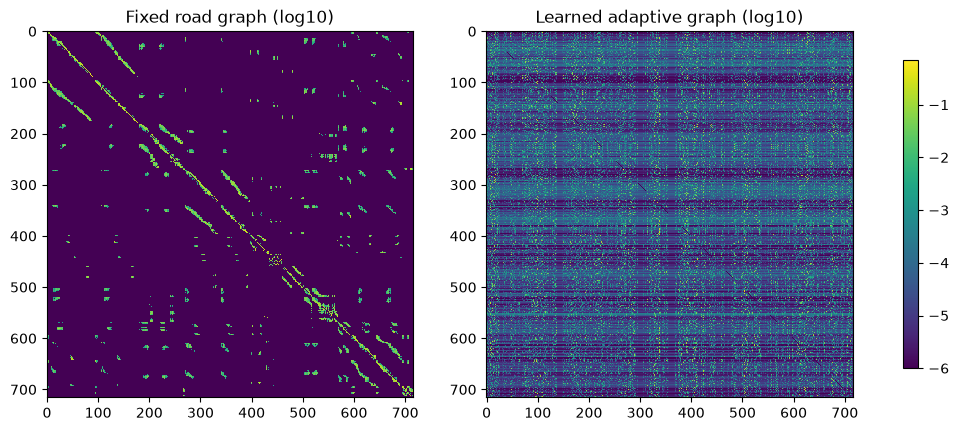

In [40]:
# Cell 4 – Show results
print(f"Learned alpha = {alpha_final:.3f}")
display(results_table(["stgnn_fixed", "stgnn_adaptive", "stgnn_hybrid"]))
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
show_adjacency(ax[0], A_hat_fixed, "Fixed road graph (log10)")
im = show_adjacency(ax[1], A_learned, "Learned adaptive graph (log10)")
fig.colorbar(im, ax=ax, shrink=0.8)
savefig("q5_fixed_vs_learned_adjacency.png"); plt.show()

## Q6(a) – Forecasting comparison

In [41]:
# Cell 1 – Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

In [42]:
# Cell 2 – Helper functions
@torch.no_grad()
def predict(model, split, starts, batch_size=256):
    model.eval()
    out = [(model(get_batch(split, starts[s:s + batch_size])[0]) * STD_T + MEAN_T).clamp(min=0).cpu().numpy()
           for s in range(0, len(starts), batch_size)]
    return np.concatenate(out)          # (windows, 4, N)

@torch.no_grad()
def per_horizon_mae(model, split, batch_size=256):
    model.eval()
    abs_sum, count = torch.zeros(T_OUT), torch.zeros(T_OUT)
    for s in range(0, len(split["starts"]), batch_size):
        x, y, m = get_batch(split, split["starts"][s:s + batch_size])
        abs_sum += (((model(x) * STD_T + MEAN_T).clamp(min=0) - y).abs() * m).sum(dim=(0, 2)).cpu()
        count += m.sum(dim=(0, 2)).cpu()
    return (abs_sum / count).numpy()

In [43]:
# Cell 3 – Calling the functions
ALL = ["temporal_only", "stgnn_fixed", "stgnn_adaptive", "stgnn_hybrid"]
MODELS = dict(zip(ALL, [model_temporal, model_fixed, model_adaptive, model_hybrid]))
final_table = results_table(ALL)
final_table.to_csv(os.path.join(OUT_DIR, "final_results.csv"), index=False)
horizon_table = pd.DataFrame({RESULTS[n]["Adjacency"]: per_horizon_mae(MODELS[n], data["test"]) for n in ALL},
                             index=[f"+{15 * (h + 1)} min" for h in range(T_OUT)]).round(2)

H_PLOT = 0                                                  # 0 = 15 min ahead
test = data["test"]
week_start = test["index"].get_loc(pd.Timestamp("2021-04-05 00:00"))
plot_starts = np.arange(week_start - 1 - H_PLOT, week_start - 1 - H_PLOT + 7 * 96)
target_idx = torch.as_tensor(plot_starts + 1 + H_PLOT, device=DEVICE)
plot_time = test["index"][plot_starts + 1 + H_PLOT]
preds = {n: predict(MODELS[n], test, plot_starts)[:, H_PLOT, :] for n in ALL}
actual = test["y"][target_idx].cpu().numpy()
actual[~test["mask"][target_idx].cpu().numpy()] = np.nan
plot_cols = [sensor_ids.index(s) for s in plot_sensors]

,Model,Adjacency,Val MAE,Val RMSE,Test MAE,Test RMSE,Training time (s),Epochs,Params
0,Temporal-only,None,52.96,85.37,61.58,96.77,723.40,30,8548
1,STGNN,Fixed,49.38,79.77,58.42,92.09,743.21,29,8548
2,STGNN,Adaptive,43.24,70.23,52.46,83.07,766.96,30,22868
3,STGNN,Hybrid,43.49,70.67,52.68,83.43,775.99,30,22869


,None,Fixed,Adaptive,Hybrid
+15 min,43.860001,42.570000,39.860001,39.790001
+30 min,56.660000,53.830002,49.099998,49.340000
+45 min,67.500000,63.610001,56.830002,57.360001
+60 min,78.300003,73.669998,64.059998,64.239998


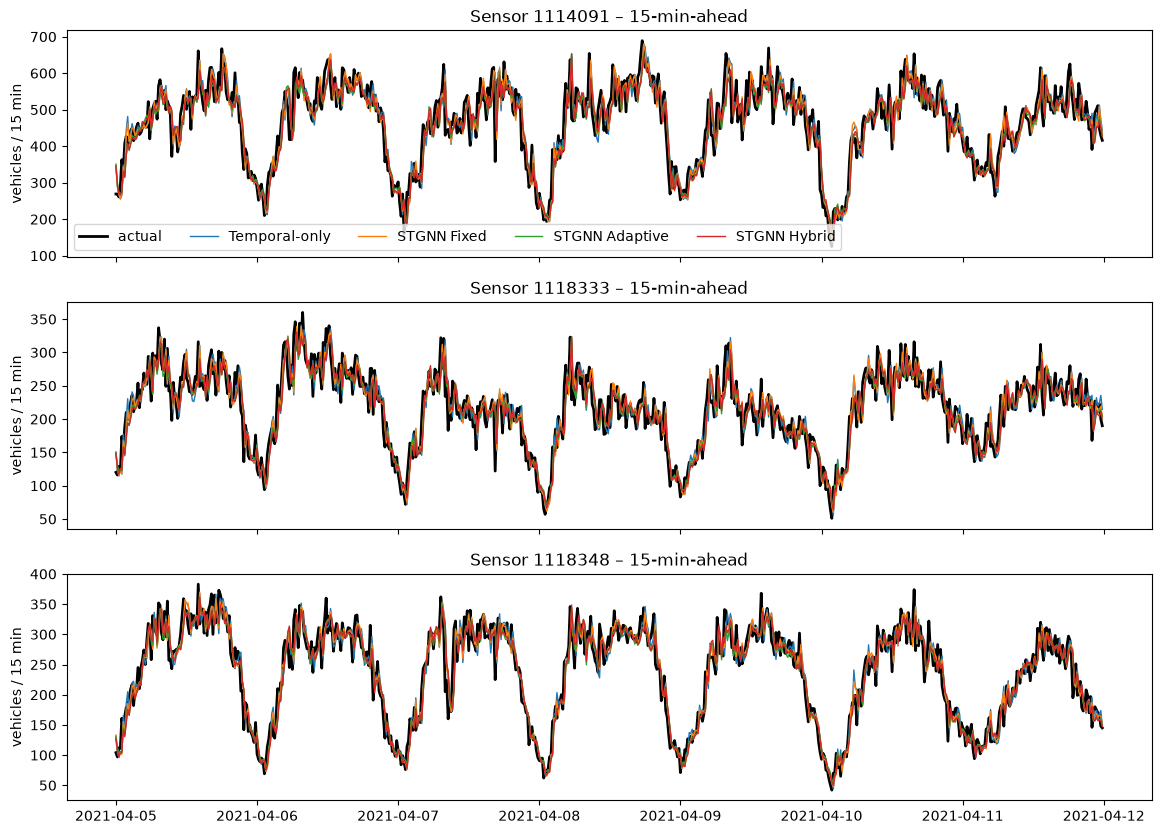

In [44]:
# Cell 4 – Show results
display(final_table)
display(horizon_table)
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, c in zip(axes, plot_cols):
    ax.plot(plot_time, actual[:, c], "k", lw=2, label="actual")
    for n in ALL:
        ax.plot(plot_time, preds[n][:, c], lw=1, label="Temporal-only" if n == "temporal_only" else "STGNN " + RESULTS[n]["Adjacency"])
    ax.set_title(f"Sensor {sensor_ids[c]} – 15-min-ahead"); ax.set_ylabel("vehicles / 15 min")
axes[0].legend(ncol=5)
savefig("q6a_pred_vs_actual.png"); plt.show()

## Q6(b) – Graph structure analysis (top-10 learned links per sensor)

In [45]:
# Cell 1 – Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [46]:
# Cell 2 – Helper functions
def haversine_km(lat, lng):
    lat, lng = np.radians(lat), np.radians(lng)
    a = (np.sin((lat[:, None] - lat[None, :]) / 2) ** 2 +
         np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin((lng[:, None] - lng[None, :]) / 2) ** 2)
    return 2 * 6371 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def top_k_edges(A, k):
    A = A.copy(); np.fill_diagonal(A, -np.inf)
    return np.repeat(np.arange(A.shape[0]), k), np.argsort(-A, axis=1)[:, :k].ravel()

def analyse_learned_graph(A_learned, A_nd, dist, k):
    r, c = top_k_edges(A_learned, k)
    road = A_nd > 0
    either = road | road.T
    B = road.astype(np.float32)
    within2 = (B + B @ B) > 0
    off = ~np.eye(len(A_nd), dtype=bool)
    return pd.Series({
        "% in road graph": 100 * either[r, c].mean(),
        "% within 2 road hops": 100 * within2[r, c].mean(),
        "% new links (not in road graph)": 100 * (~either[r, c]).mean(),
        "random baseline % (road density)": 100 * either[off].mean(),
        "median km learned links": np.median(dist[r, c]),
        "median km road links": np.median(dist[road]),
        "median km random pairs": np.median(dist[off])}), r, c

In [47]:
# Cell 3 – Calling the functions
K_TOP = 10
dist_km = haversine_km(sd_meta.Lat.values, sd_meta.Lng.values)
graph_summary, r_top, c_top = analyse_learned_graph(A_learned, A_nd, dist_km, K_TOP)
road_mask = A_nd > 0
off_diag = ~np.eye(len(A_nd), dtype=bool)
r1, c1 = top_k_edges(A_learned, 1)
in_road_1 = (road_mask | road_mask.T)[r1, c1]

% in road graph                      5.11
% within 2 road hops                11.66
% new links (not in road graph)     94.89
random baseline % (road density)     4.11
median km learned links             21.25
median km road links                 2.37
median km random pairs              23.02


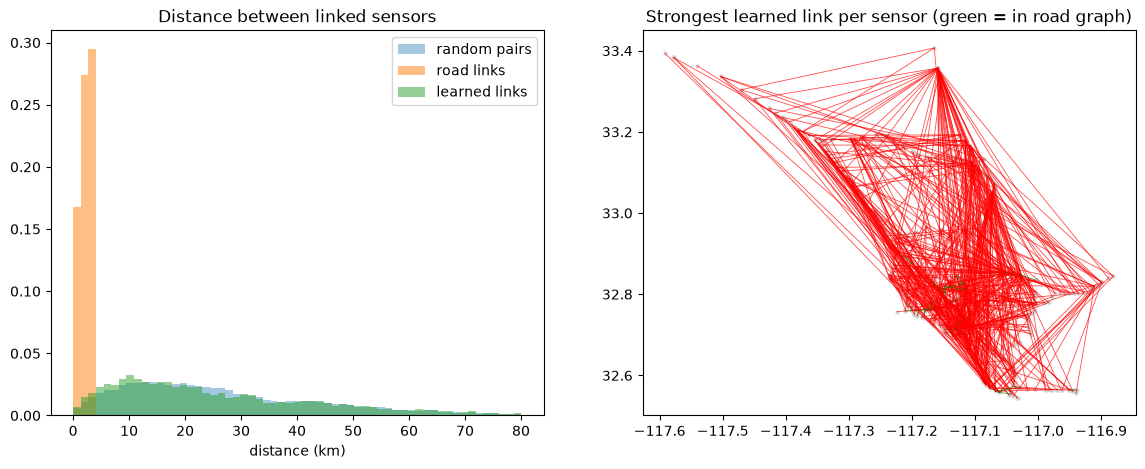

In [48]:
# Cell 4 – Show results
print(graph_summary.round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
bins = np.linspace(0, np.percentile(dist_km[off_diag], 99), 60)
ax[0].hist(dist_km[off_diag], bins, density=True, alpha=0.4, label="random pairs")
ax[0].hist(dist_km[road_mask], bins, density=True, alpha=0.5, label="road links")
ax[0].hist(dist_km[r_top, c_top], bins, density=True, alpha=0.5, label="learned links")
ax[0].set_xlabel("distance (km)"); ax[0].legend(); ax[0].set_title("Distance between linked sensors")
ax[1].scatter(sd_meta.Lng, sd_meta.Lat, s=4, c="lightgrey")
for a_, b_, ok in zip(r1, c1, in_road_1):
    ax[1].plot([sd_meta.Lng[a_], sd_meta.Lng[b_]], [sd_meta.Lat[a_], sd_meta.Lat[b_]],
               c="green" if ok else "red", lw=0.6, alpha=0.7)
ax[1].set_title("Strongest learned link per sensor (green = in road graph)")
savefig("q6b_learned_graph_analysis.png"); plt.show()

## Q7 – Reproducibility 

In [49]:
# Cell 1 – Imports
import json, platform, subprocess
import torch

In [50]:
# Cell 2 – Helper functions
def hardware_info():
    info = {"OS": platform.platform(), "Python": platform.python_version(),
            "PyTorch": torch.__version__, "Device": str(DEVICE)}
    try:
        info["Chip"] = subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"], stderr=subprocess.DEVNULL).decode().strip()
        info["RAM (GB)"] = round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"], stderr=subprocess.DEVNULL)) / 1e9, 1)
    except Exception:
        info["Chip"] = platform.processor()
    return info

def md_table(df):
    df = df.astype(str)
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(row) + " |" for row in df.values]
    return "\n".join(lines)

def fig(name, caption):
    return f"![{caption}](outputs/figures/{name})\n\n*{caption}*\n"

### Show results

In [171]:
print(json.dumps(json.load(open(os.path.join(OUT_DIR, "run_config.json"))), indent=2))

{
  "hardware": {
    "OS": "macOS-27.2.1-arm64-arm-64bit-Mach-O",
    "Python": "3.14.2",
    "PyTorch": "2.15.0",
    "Device": "mps",
    "Chip": "Apple M2 Pro",
    "RAM (GB)": 17.2
  },
  "seed": 42,
  "hyperparameters": {
    "d_hidden": 32,
    "emb_dim": 10,
    "lr": 0.001,
    "batch_size": 64,
    "epochs": 30,
    "patience": 5,
    "grad_clip": 5.0,
    "seed": 42
  },
  "splits": {
    "train": [
      "2020-01-01 00:00",
      "2020-12-31 23:45"
    ],
    "val": [
      "2021-01-01 00:00",
      "2021-03-31 23:45"
    ],
    "test": [
      "2021-04-01 00:00",
      "2021-12-31 23:45"
    ]
  },
  "epochs": {
    "temporal_only": 30,
    "stgnn_fixed": 29,
    "stgnn_adaptive": 30,
    "stgnn_hybrid": 30
  },
  "training_time_s": {
    "temporal_only": 723.4,
    "stgnn_fixed": 743.2,
    "stgnn_adaptive": 767.0,
    "stgnn_hybrid": 776.0
  }
}
